#### [PREV](3.OOP_Polynomial_Liner_Regression.ipynb) | [HOME](../README.md) | [NEXT](5.OOP_KNN.ipynb)

---

# OOP Logistic Regression Implementation

This Jupyter Notebook provides a basic implementation of Logistic Regression for classification. The data set contains measurements on a single species of insect captured on two continents. We want to predict which continent (0 or 1) an insect was captured on given the other measurements we have (wing size, latitude and sex).

#### Step 1: Import Dependencies

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, mean_squared_error

#### Step 2: Import And Visualise The Data

In [2]:
# Import data as a Pandas DataFrame
insects = pd.read_csv('./data/insects.csv', sep='\t')
insects = pd.DataFrame({
    'continent': insects['continent'],
    'latitude': insects['latitude'],
    'sex': insects['sex'],
    'wingsize': insects['wingsize']
})

# Features variable
X_insects = insects[['wingsize', 'latitude', 'sex']]
# Target variable
y_insects = insects['continent']

insects.head()

,continent,latitude,sex,wingsize
0,1,35.5,0,901
1,1,37.0,0,896
2,1,38.6,0,906
3,1,40.7,0,907
4,1,40.9,0,898


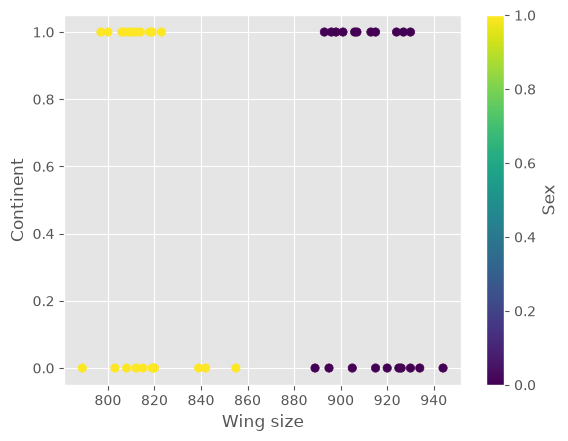

In [3]:
# Plot the data, colour coded by sex
plt.scatter(insects.wingsize, insects.continent, c=insects['sex'])
plt.xlabel("Wing size")
plt.ylabel("Continent")
plt.colorbar(label="Sex")
plt.show()

#### Step 3: Instantiate a LogisticRegression Object

In [4]:
# max_iter is increased so the solver has enough iterations to find the best fit (converge)
insects_regression = LogisticRegression(max_iter=1000)

#### Step 4: Fit the model

In [5]:
insects_regression.fit(X_insects, y_insects)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Now that the model has been fit, we can use the `predict` method to predict which continent (0 or 1) the model thinks an insect was captured on.

In [7]:
# Predict the target for the whole dataset
insects_predictions = insects_regression.predict(X_insects)

# Predict the target for a new data point
new_insect = pd.DataFrame({
    'wingsize': [900],
    'latitude': [40],
    'sex': [0]
})
new_insect['continent'] = insects_regression.predict(new_insect)
print(f"New insect is:\n{new_insect}")

New insect is:
   wingsize  latitude  sex  continent
0       900        40    0          1


Additionally (and in many cases more usefully), the `LogisticRegression` has a `predict_proba` method that produces a predicted **probability**.

In [8]:
# Predict the probabilities for the whole dataset
insects_probabilities = insects_regression.predict_proba(X_insects)

# Predict the probabilities for a new data point
new_insect = pd.DataFrame({
    'wingsize': [900],
    'latitude': [40],
    'sex': [0]
})
new_insect_probabilities = insects_regression.predict_proba(new_insect)
print(f"Probabilities for new insect [continent 0, continent 1]:\n{new_insect_probabilities}")

Probabilities for new insect [continent 0, continent 1]:
[[0.38308497 0.61691503]]


#### Step 5: Plot the Predictions

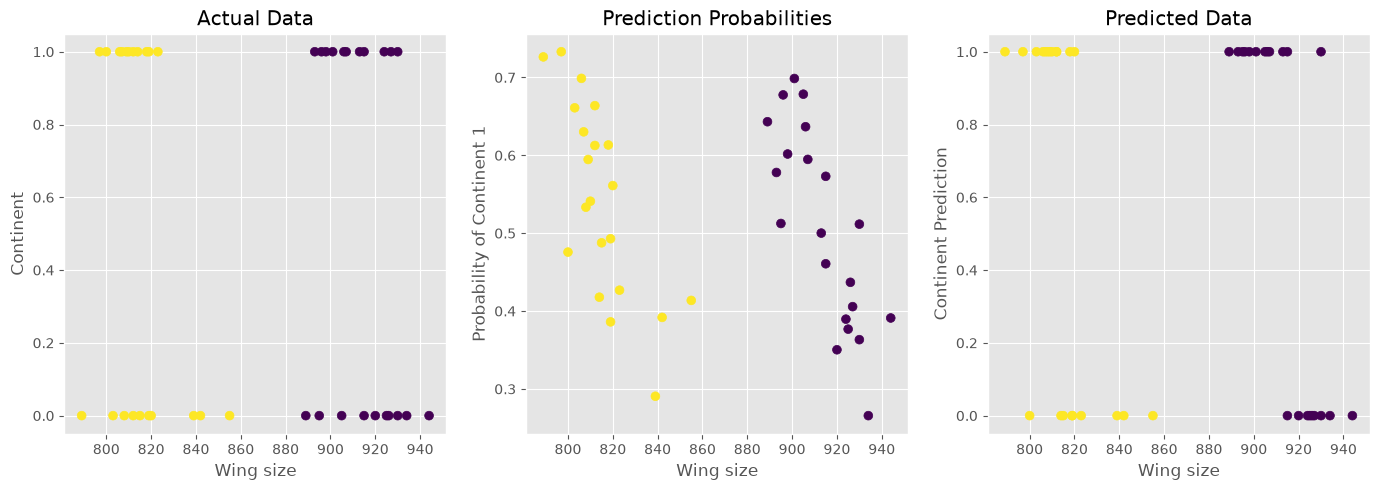

In [9]:
# Plot the predictions compared to the actual data
fig, axs = plt.subplots(1, 3, figsize=(14, 5))

axs[0].scatter(insects.wingsize, insects.continent, s=40, c=insects['sex'])
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Wing size")
axs[0].set_ylabel("Continent")

axs[1].scatter(insects.wingsize, insects_probabilities[:, 1], s=40, c=insects['sex'])
axs[1].set_title("Prediction Probabilities")
axs[1].set_xlabel("Wing size")
axs[1].set_ylabel("Probability of Continent 1")

axs[2].scatter(insects.wingsize, insects_predictions, s=40, c=insects['sex'])
axs[2].set_title("Predicted Data")
axs[2].set_xlabel("Wing size")
axs[2].set_ylabel("Continent Prediction")

plt.tight_layout()
plt.show()

#### Step 6: Evaluate The Model

In [10]:
# Get evaluative data from the model
accuracy = accuracy_score(y_true=y_insects, y_pred=insects_predictions)
print(f"Accuracy: {accuracy:.3f}")
print("Confusion matrix (rows = actual continent, columns = predicted continent):")
print(confusion_matrix(y_true=y_insects, y_pred=insects_predictions))

# MAE and MSE compare the predicted probabilities with the actual continent (lower is better)
mae = mean_absolute_error(y_true=y_insects, y_pred=insects_probabilities[:, 1])
mse = mean_squared_error(y_true=y_insects, y_pred=insects_probabilities[:, 1])
print("MAE:", mae)
print("MSE:", mse)

Accuracy: 0.571
Confusion matrix (rows = actual continent, columns = predicted continent):
[[10 10]
 [ 8 14]]
MAE: 0.4668839798239841
MSE: 0.2327758162295096


In [11]:
# Optional: Manually evaluate the loss and cost of the model
model_loss = pd.DataFrame({
    'Target': y_insects,
    'Predicted result': insects_predictions,
    'Loss': (insects_predictions != y_insects).astype(int)  # 1 = wrong prediction, 0 = correct
})
# Cost = the fraction of predictions that were wrong (the error rate)
model_cost = model_loss['Loss'].mean()

print(f"The cost (error rate) of this model is {model_cost:.5f}")
print(f"The model predicted incorrectly {model_loss['Loss'].sum()} times out of {model_loss.shape[0]} predictions")
print(model_loss)

The cost (error rate) of this model is 0.42857
The model predicted incorrectly 18 times out of 42 predictions
    Target  Predicted result  Loss
0        1                 1     0
1        1                 1     0
2        1                 1     0
3        1                 1     0
4        1                 1     0
5        1                 1     0
6        1                 1     0
7        1                 0     1
8        1                 0     1
9        1                 0     1
10       1                 0     1
11       0                 1     1
12       0                 1     1
13       0                 1     1
14       0                 1     1
15       0                 1     1
16       0                 0     0
17       0                 0     0
18       0                 0     0
19       0                 0     0
20       0                 0     0
21       1                 1     0
22       1                 1     0
23       1                 1     0
24       1     